In [89]:
# импортируем библиотеки
import numpy as np
import matplotlib.pyplot as plt
from math import factorial
import random
import math


# **4 Листок**
### Листок № 5. Классическое, статистическое, геометрическое определение вероятности
*Составитель: д.ф.-м.н., проф. Рябов П.Е.*

> Ко всем задачам, где есть числовой ответ, напишите программу (код) с использованием инструментария **Jupyter Notebook**, который иллюстрирует график зависимости относительной частоты $\hat{p}(A) \stackrel{\text{def}}{=} \frac{N(A)}{N}$ события $A$ от числа проведенных реализаций опыта $N$.

**4.1.** Корзина содержит 23 шара: 8 белых, 6 синих и 9 красных. На каждом шаге из корзины «наудачу» извлекается шар и назад в корзину не возвращается. Исход $n$ последовательных извлечений называется выборкой объема $n$ без возвращения или бесповторной выборкой. Из корзины наудачу (без возвращения) извлечены 6 шаров. Найдите вероятности следующих событий и покажите их статистическую устойчивость:

**а)** $A = \{\text{все шары красные}\};$

**б)** $B = \{3 \text{ синих}, 2 \text{ белых и } 1 \text{ красный}\};$

**в)** $D = \{\text{в точности } 4 \text{ белых шара}\}.$

**г)** Разобрать случай извлечения шаров *с возвращением*. Найдите вероятность $\mathbb{P}(A)$ события $A$, если «статистическая вероятность» равна $\hat{p}(A) \approx 0{,}00358549$.

*Ответ из методички:*
* **а)** точный ответ $\mathbb{P}(A) = \frac{4}{4807} \approx 0{,}0008321198252548367$;
* **г)** для случая извлечения шаров с возвращением $\hat{p}(A) \approx 0{,}00358549$.


In [90]:
def combination(m, M):
    return factorial(M)/(factorial(m)*factorial(M-m))

A = combination(6, 9) / combination(6, 23)
B = combination(3, 6) * combination(2, 8) * combination(1, 9) / combination(6, 23)
D = combination(4, 8) * combination(2, 15) / combination(6, 23)
E = (9 / 23) ** 6

print(f'P(A) = {A}')
print(f'P(B) = {B}')
print(f'P(D) = {D}')
print(f'P(A) = {E} (с возвращением)')

P(A) = 0.0008321198252548367
P(B) = 0.0499271895152902
P(D) = 0.07281048470979821
P(A) = 0.0035899470296692727 (с возвращением)


In [91]:
box = [0]*8 + [1]*6 + [2]*9

# Универсальная функция построения графика статистической устойчивости
def plot_stability(sim_func, p_theor, N=100_000, title="График статистической устойчивости", y_limits=None):
    res = [sim_func() for _ in range(N)]
    cumsum = np.cumsum(res)
    trials = np.arange(1, N + 1)
    p_hat = cumsum / trials

    plt.figure(figsize=(9, 4.8))
    plt.plot(trials, p_hat, 'b-', lw=1.2, label=r'$\hat{p}$ (относительная частота)')
    plt.axhline(y=p_theor, color='red', lw=1.5, label=f'Теория P = {p_theor:.6f}')
    
    if y_limits is not None:
        plt.ylim(y_limits)
    else:
        delta = max(p_theor * 0.35, 0.005)
        plt.ylim(max(0, p_theor - delta), min(1, p_theor + delta))
        
    plt.xlim(0, N)
    plt.title(title, fontsize=11)
    plt.xlabel('Число проведенных опытов N')
    plt.ylabel(r'Частота $\hat{p}$')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend()
    plt.show()
    print(f'Оценка вероятности: p_hat = {p_hat[-1]:.6f} (теория = {p_theor:.6f})')

# Функции симуляции для задачи 4.1
def sim_4_1_a():
    return np.all(np.random.choice(box, size=6, replace=False) == 2)

def sim_4_1_g():
    return np.all(np.random.choice(box, size=6, replace=True) == 2)


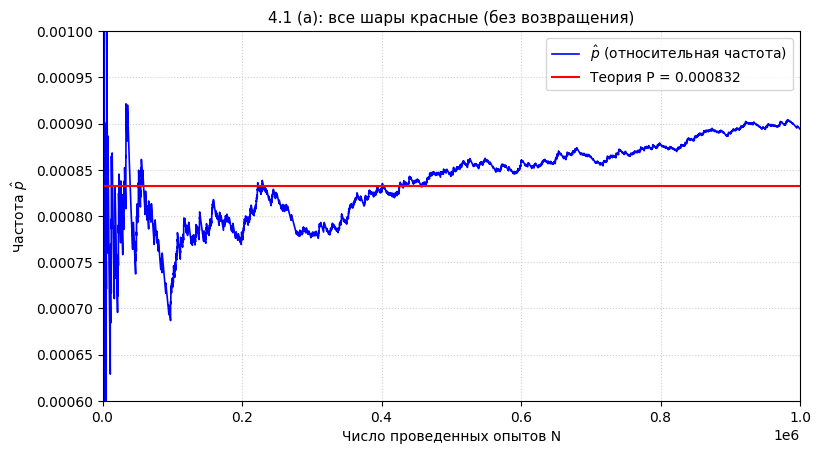

Оценка вероятности: p_hat = 0.000894 (теория = 0.000832)


In [92]:
plot_stability(sim_4_1_a, A, N=1_000_000, title="4.1 (а): все шары красные (без возвращения)", y_limits=(0.0006, 0.0010))


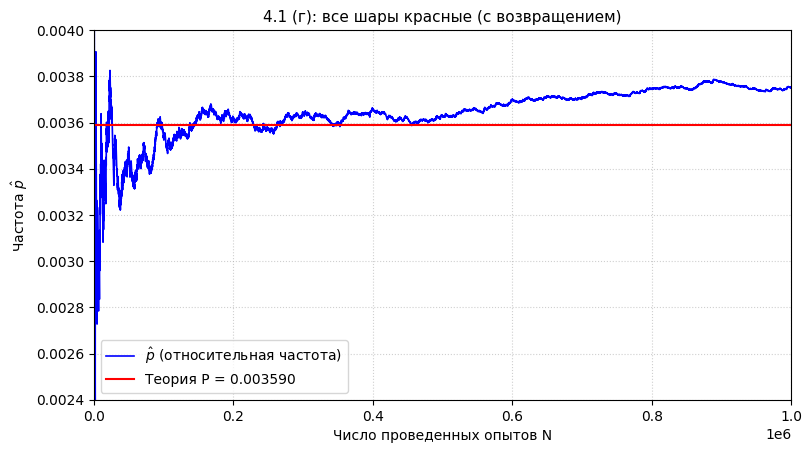

Оценка вероятности: p_hat = 0.003750 (теория = 0.003590)


In [93]:
plot_stability(sim_4_1_g, E, N=1_000_000, title="4.1 (г): все шары красные (с возвращением)", y_limits=(0.0024, 0.0040))


**4.2.** 5 мужчин и 5 женщин случайным образом рассаживаются в ряд на 10 мест. Найдите вероятности следующих событий:

* $A$ — любые две женщины не сидят рядом;
* $B$ — все мужчины сидят рядом.

*Ответ из методички:* $\mathbb{P}(A) = \mathbb{P}(B) = \frac{1}{42}$.


P(A) = 0.023809523809523808 | theor 0.023809523809523808
P(B) = 0.023809523809523808 | theor 0.023809523809523808


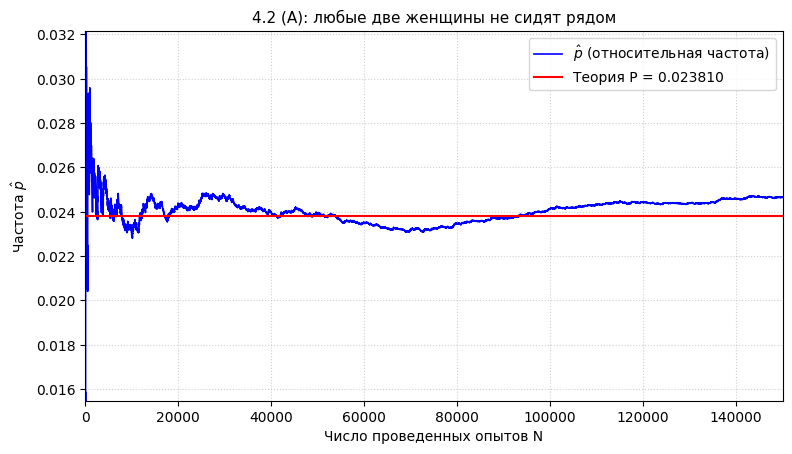

Оценка вероятности: p_hat = 0.024653 (теория = 0.023810)


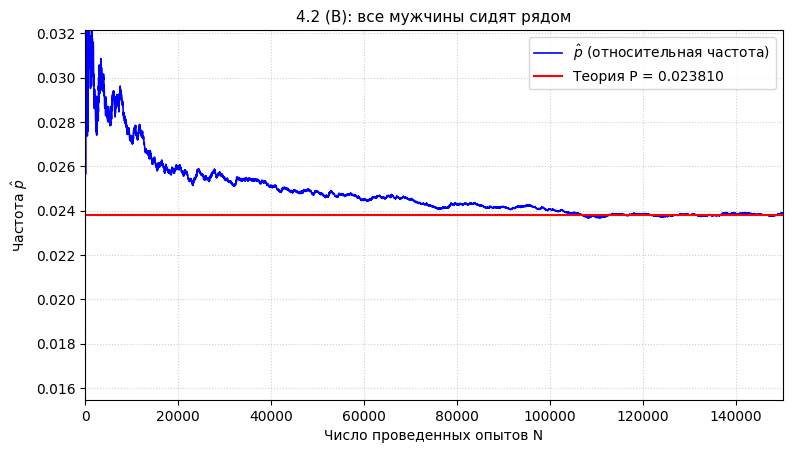

Оценка вероятности: p_hat = 0.023893 (теория = 0.023810)


In [94]:
A = factorial(5) * factorial(5) * combination(5, 6) / factorial(10)
B = factorial(5) * factorial(6) / factorial(10)
theor = 1 / 42

print(f'P(A) = {A} | theor {theor}')
print(f'P(B) = {B} | theor {theor}')

# 0 - женщина, 1 - мужчина
row_base = np.array([0]*5 + [1]*5)

# Событие A: любые две женщины не сидят рядом (нет двух нулей подряд)
def sim_4_2_a():
    r = np.random.permutation(row_base)
    return not np.any((r[:-1] == 0) & (r[1:] == 0))

# Событие B: все мужчины сидят рядом (все единицы идут подряд)
def sim_4_2_b():
    r = np.random.permutation(row_base)
    men_pos = np.where(r == 1)[0]
    return (men_pos[-1] - men_pos[0]) == 4

plot_stability(sim_4_2_a, theor, N=150_000, title="4.2 (A): любые две женщины не сидят рядом")
plot_stability(sim_4_2_b, theor, N=150_000, title="4.2 (B): все мужчины сидят рядом")


**4.3.** Предположим, что «симметричную» монету бросают до первого появления герба. Найдите вероятность события $A$, состоящего в том, что будет произведено не более пяти бросаний.


P(A) = 0.96875 (31/32 = 0.96875)


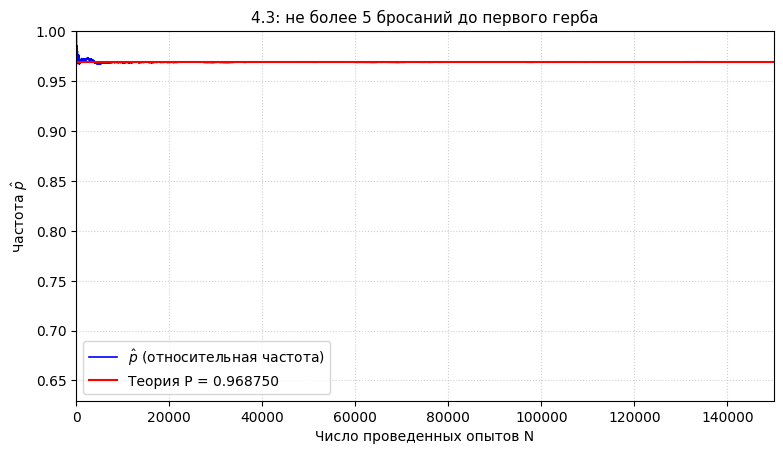

Оценка вероятности: p_hat = 0.969020 (теория = 0.968750)


In [95]:
P = 1 - 1 / 32
print(f'P(A) = {P:.5f} (31/32 = {31/32})')

# Бросаем симметричную монету до первого появления герба
def sim_4_3():
    count = 0
    while True:
        count += 1
        if random.random() < 0.5:
            break
    return count <= 5

plot_stability(sim_4_3, P, N=150_000, title="4.3: не более 5 бросаний до первого герба")


**4.4.** Предположим, что «симметричную» монету бросают до тех пор, пока она не выпадет дважды одной и той же стороной подряд. Построить вероятностную модель, т.е. $(\Omega, \mathbb{P}(\cdot))$ и найдите вероятность того, что потребуется чётное число бросаний.

*Ответ из методички:* $\frac{2}{3}$.


In [96]:
def prob_model(k, x_sign='O', y_sign='P'):
    if k < 2:
        raise ValueError('Число бросков должно быть >= 2')
    X = ''
    Y = ''

    X = ''.join(x_sign if i % 2 == 0 else y_sign for i in range(k - 1))
    Y = ''.join(y_sign if i % 2 == 0 else x_sign for i in range(k - 1))

    X += X[-1]
    Y += Y[-1]

    return X, Y, 0.5**k, 0.5**k

print(prob_model(3))

s = 0
for k in range(1, 100):
    X, Y, prob_x, prob_y = prob_model(2*k)
    s += prob_x + prob_y

    print(f's = {s}, при k = {k}')


('OPP', 'POO', 0.125, 0.125)
s = 0.5, при k = 1
s = 0.625, при k = 2
s = 0.65625, при k = 3
s = 0.6640625, при k = 4
s = 0.666015625, при k = 5
s = 0.66650390625, при k = 6
s = 0.6666259765625, при k = 7
s = 0.666656494140625, при k = 8
s = 0.6666641235351562, при k = 9
s = 0.6666660308837891, при k = 10
s = 0.6666665077209473, при k = 11
s = 0.6666666269302368, при k = 12
s = 0.6666666567325592, при k = 13
s = 0.6666666641831398, при k = 14
s = 0.666666666045785, при k = 15
s = 0.6666666665114462, при k = 16
s = 0.6666666666278616, при k = 17
s = 0.6666666666569654, при k = 18
s = 0.6666666666642413, при k = 19
s = 0.6666666666660603, при k = 20
s = 0.6666666666665151, при k = 21
s = 0.6666666666666288, при k = 22
s = 0.6666666666666572, при k = 23
s = 0.6666666666666643, при k = 24
s = 0.6666666666666661, при k = 25
s = 0.6666666666666665, при k = 26
s = 0.6666666666666666, при k = 27
s = 0.6666666666666666, при k = 28
s = 0.6666666666666666, при k = 29
s = 0.6666666666666666, при k 

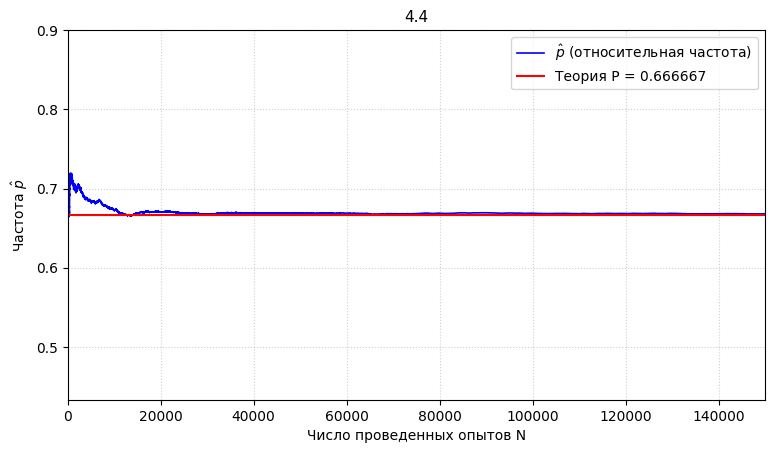

Оценка вероятности: p_hat = 0.668107 (теория = 0.666667)


In [97]:
def sim_4_4():
    prev = random.randint(0, 1)
    count = 1
    while True:
        cur = random.randint(0, 1)
        count += 1
        if cur == prev:
            break
        prev = cur

    return count % 2 == 0

plot_stability(sim_4_4, 2/3, N=150_000, title='4.4')

**4.5.** Предположим, что «несимметричную» («неправильную») монету бросают до тех пор, пока она не выпадет дважды одной и той же стороной подряд (вероятность выпадения «герба» равна $p = 0{,}7$). Постройте вероятностную модель, т.е. $(\Omega, \mathbb{P}(\cdot))$ и найдите вероятность того, что потребуется:

**а)** чётное число бросаний;

**б)** число бросаний кратно 4.


In [98]:
def prob_model_2(k, p=0.7, x_sign='O', y_sign='P'):
    if k < 2:
        raise ValueError('Число бросков должно быть >= 2')

    q = 1 - p
    X, Y = '', ''
    chance_X, chance_Y = 1.0, 1.0

    for throw in range(k - 1):
        if throw % 2 == 0:
            X += x_sign
            Y += y_sign
            chance_X *= p
            chance_Y *= q
        else:
            Y += x_sign
            X += y_sign
            chance_Y *= p
            chance_X *= q

    X += X[-1]
    Y += Y[-1]
    chance_X *= p if X[-1] == x_sign else q
    chance_Y *= p if Y[-1] == x_sign else q

    return X, Y, chance_X, chance_Y

print(prob_model_2(3))

s = 0
s2 = 0
for k in range(1, 100):
    X, Y, prob_x, prob_y = prob_model_2(2*k)
    X2, Y2, prob_x2, prob_y2 = prob_model_2(4*k)

    s += prob_x + prob_y
    s2 += prob_x2 + prob_y2

    print(f'а)s = {s}, при k = {k}; б)s = {s2}, при k = {k}')


('OPP', 'POO', 0.06300000000000001, 0.147)
а)s = 0.58, при k = 1; б)s = 0.12179999999999999, при k = 1
а)s = 0.7018, при k = 2; б)s = 0.12717138, при k = 2
а)s = 0.727378, при k = 3; б)s = 0.127408257858, при k = 3
а)s = 0.73274938, при k = 4; б)s = 0.1274187041715378, при k = 4
а)s = 0.7338773698, при k = 5; б)s = 0.12741916485396482, при k = 5
а)s = 0.7341142476579999, при k = 6; б)s = 0.12741918517005985, при k = 6
а)s = 0.7341639920081799, при k = 7; б)s = 0.12741918606599964, при k = 7
а)s = 0.7341744383217177, при k = 8; б)s = 0.1274191861055106, при k = 8
а)s = 0.7341766320475607, при k = 9; б)s = 0.12741918610725303, при k = 9
а)s = 0.7341770927299877, при k = 10; б)s = 0.12741918610732986, при k = 10
а)s = 0.7341771894732974, при k = 11; б)s = 0.12741918610733324, при k = 11
а)s = 0.7341772097893924, при k = 12; б)s = 0.12741918610733338, при k = 12
а)s = 0.7341772140557723, при k = 13; б)s = 0.12741918610733338, при k = 13
а)s = 0.7341772149517121, при k = 14; б)s = 0.1274191

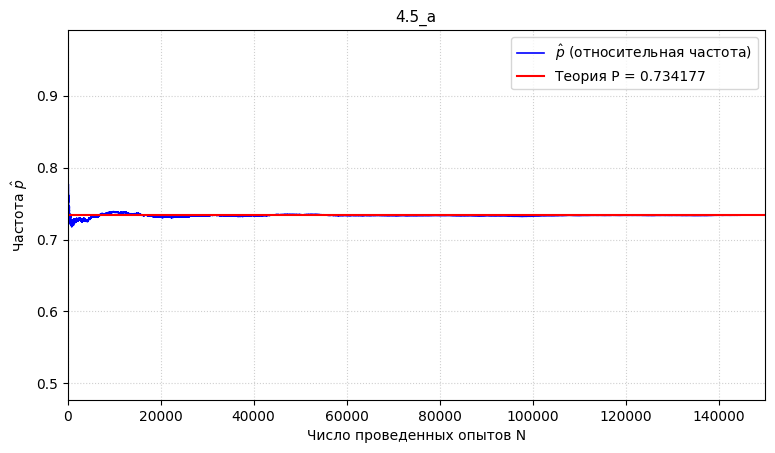

Оценка вероятности: p_hat = 0.734067 (теория = 0.734177)


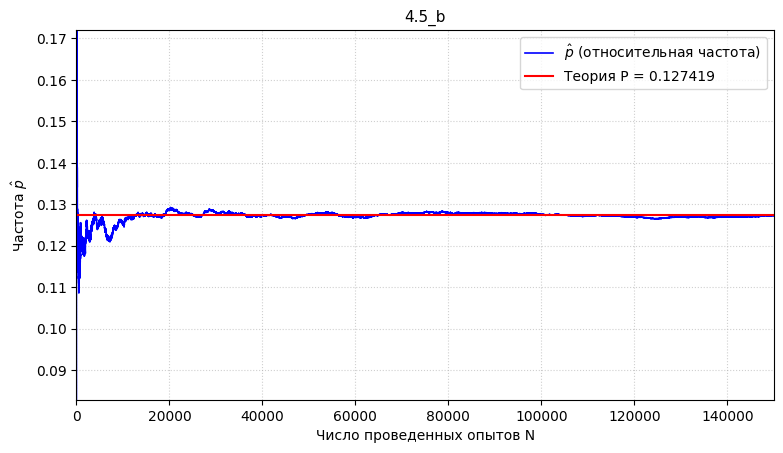

Оценка вероятности: p_hat = 0.127207 (теория = 0.127419)


In [99]:
def sim_4_5(mod, p = 0.7):
    prev = random.random() < p
    count = 1
    while True:
        curr = random.random() < p
        count += 1
        if curr == prev:
            break
        prev = curr

    return count % mod == 0

plot_stability(lambda: sim_4_5(2, 0.7), 0.7341772151898731, N=150_000, title='4.5_a')
plot_stability(lambda: sim_4_5(4, 0.7), 0.12741918610733338, N=150_000, title='4.5_b')

**4.6.** Два лица $A$ и $B$ условились встретиться в определенном месте между двумя и тремя часами дня. Лицо $A$ ждет другого в течение 10 минут, после чего уходит; лицо $B$ ждет другого в течение 12 минут. Считая, что момент прихода на встречу выбирается каждым «наудачу» в пределах указанного часа, найдите вероятность, что встреча состоится. Постройте график зависимости относительной частоты $\hat{p}(A) \stackrel{\text{def}}{=} \frac{N(A)}{N}$ события $A$ от числа проведенных реализаций опыта $N = 150\,000$ и приведите оценку вероятности $\hat{p}(A) = \frac{N_A}{N}$ для $N = 150\,000$.

*Ответ из методички:* точный ответ $\approx 0{,}332778$; оценка $\hat{p} \approx 0{,}33268$.


In [100]:
def prob_model_4_6(A_start, B_start, A=10, B=12, T=60):
    return B_start - A_start <= A if B_start > A_start else A_start - B_start <= B

cnt = 0.0
for a in range(60):
    for b in range(60):
        diff = b - a
        if -12 < diff < 10:
            cnt += 1.0
        elif diff == -12 or diff == 10:
            cnt += 0.5 


P_theor = cnt / 3600
print(P_theor) 

0.3327777777777778


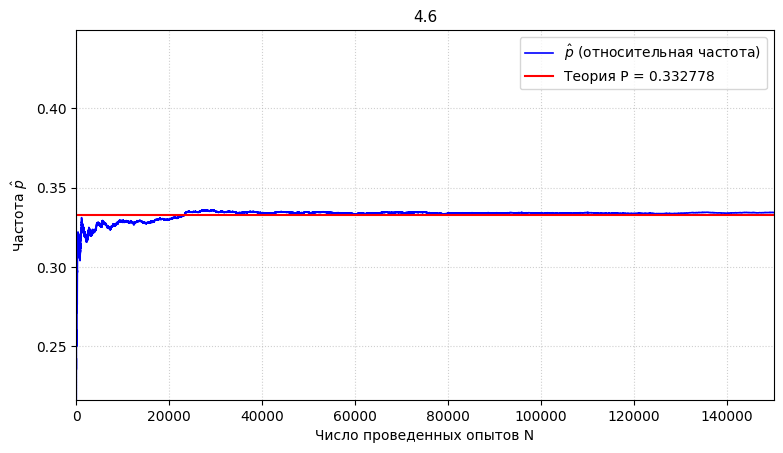

Оценка вероятности: p_hat = 0.334333 (теория = 0.332778)


In [101]:
def sim_4_6():
    a = random.uniform(0, 60)
    b = random.uniform(0, 60)

    return -12 <= (b - a) <= 10

plot_stability(sim_4_6, P_theor, N=150_000, title='4.6')

**4.7.** Иван и Пётр договорились о встрече в определённом месте между 11 и 12 часами. Каждый приходит и ждёт другого до истечения часа, но не более 15 минут. Найдите вероятности следующих событий:

* $A$ — встреча состоялась;
* $B$ — встреча не состоялась;
* $C$ — Ивану не пришлось ждать Петра;
* $D$ — встреча состоялась после 11 ч. 30 мин;
* $E$ — Иван опоздал на встречу;
* $F$ — встреча состоялась, когда до истечения часа оставалось меньше 5 минут.

Постройте график зависимости относительной частоты $\hat{p}(A) \stackrel{\text{def}}{=} \frac{N(A)}{N}$ события $A$ от числа проведенных реализаций опыта $N = 150\,000$ и приведите оценку вероятности $\hat{p}(A) = \frac{N_A}{N}$ для $N = 150\,000$.


In [102]:
def prob_model_4_7(A_start, B_start, A=15, B=15, T=60):
    return abs(A_start - B_start) <= 15

S_neg = 45*45*2/2
S_all = 60*60
S_pos = S_all - S_neg
S_neg_D = 15 * 15 * 2 / 2
print(f'P(A) = {S_pos / S_all}')
print(f'P(B) = {S_neg / S_all}')
print(f'P(C) = {(1/2) * S_pos / S_all}')
print(f'P(D) = {(S_pos - (30*30 - S_neg_D)) / S_all}')
print(f'P(E) = {(S_neg / 2) / S_all}')
print(f'P(A) = {150 / S_all}')



P(A) = 0.4375
P(B) = 0.5625
P(C) = 0.21875
P(D) = 0.25
P(E) = 0.28125
P(A) = 0.041666666666666664


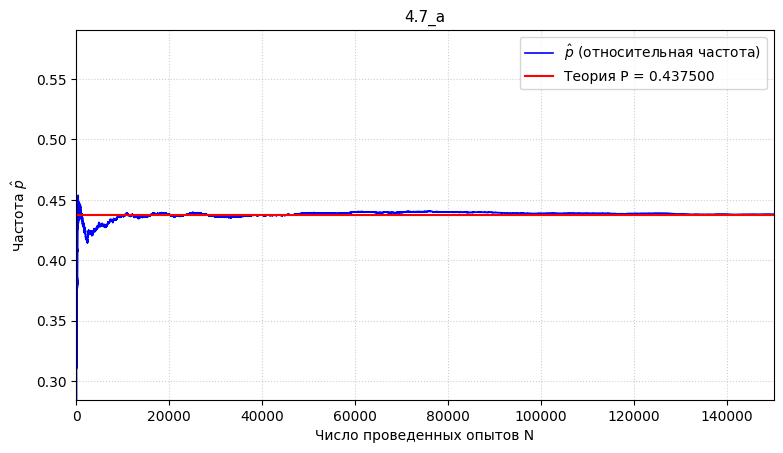

Оценка вероятности: p_hat = 0.438080 (теория = 0.437500)


In [103]:
def sim_4_7_a():
    x_i = random.uniform(0, 60)
    y_i = random.uniform(0, 60)
    return prob_model_4_7(x_i, y_i)

plot_stability(sim_4_7_a, S_pos / S_all, N=150_000, title='4.7_a')

**4.8.** На отрезке $[a, b]$, лежащем на числовой оси, наудачу выбирается первая точка с координатой $x$, после чего на отрезке $[a, x]$ наудачу выбирается вторая точка с координатой $y$. Найдите вероятности следующих событий:

* $A$ — вторая точка ближе к $b$, чем первая к $a$;
* $B$ — расстояние между точками $x$ и $y$ меньше половины длины отрезка;
* $C$ — первая точка ближе ко второй, чем к точке $b$.

Постройте график зависимости относительной частоты $\hat{p}(A) \stackrel{\text{def}}{=} \frac{N(A)}{N}$ события $A$ от числа проведенных реализаций опыта $N = 150\,000$ и приведите оценку вероятности $\hat{p}(A) = \frac{N_A}{N}$ для $N = 150\,000$.


P(A) = 0.30513 (теор: 0.30685)
P(B) = 0.84725 (теор: 0.84657)
P(C) = 0.69353 (теор: 0.69315)


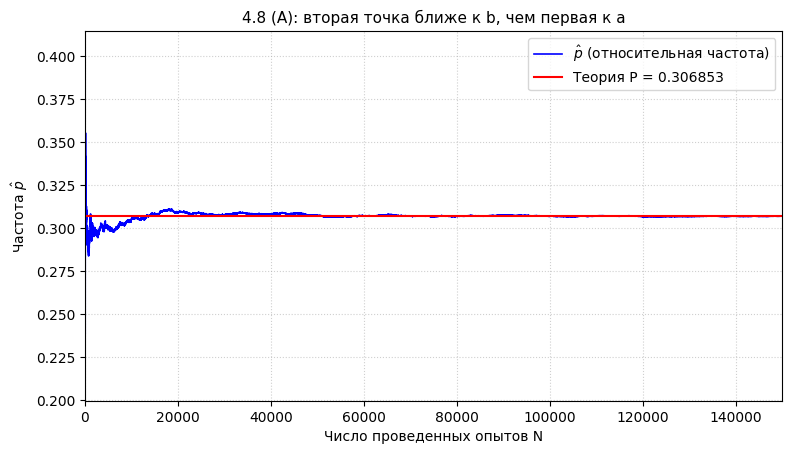

Оценка вероятности: p_hat = 0.306647 (теория = 0.306853)


In [104]:
a_val, b_val = 0.0, 1.0
P_A_4_8 = 1 - np.log(2)
P_B_4_8 = (1 + np.log(2)) / 2
P_C_4_8 = np.log(2)

N_sim = 150_000
x_pts = np.random.uniform(a_val, b_val, N_sim)
y_pts = np.random.uniform(a_val, x_pts)

ev_A = (b_val - y_pts) < (x_pts - a_val)
ev_B = (x_pts - y_pts) < (b_val - a_val) / 2
ev_C = (x_pts - y_pts) < (b_val - x_pts)

print(f'P(A) = {np.mean(ev_A):.5f} (теор: {P_A_4_8:.5f})')
print(f'P(B) = {np.mean(ev_B):.5f} (теор: {P_B_4_8:.5f})')
print(f'P(C) = {np.mean(ev_C):.5f} (теор: {P_C_4_8:.5f})')

def sim_4_8_a():
    x_i = random.uniform(a_val, b_val)
    y_i = random.uniform(a_val, x_i)
    return (b_val - y_i) < (x_i - a_val)

plot_stability(sim_4_8_a, P_A_4_8, N=150_000, title='4.8 (A): вторая точка ближе к b, чем первая к a')


**4.9.** Отрезок $[0; 1]$ случайным образом делится на 3 части. Найти вероятность того, что из полученных отрезков можно сложить треугольник и этот треугольник будет остроугольным. Постройте график зависимости относительной частоты $\hat{p}(A) \stackrel{\text{def}}{=} \frac{N(A)}{N}$ события $A$ от числа проведенных реализаций опыта $N = 150\,000$ и приведите оценку вероятности $\hat{p}(A) = \frac{N_A}{N}$ для $N = 150\,000$. Найдите аналитическое решение для вероятности.

*Ответ из методички:*
$$\Omega = \left\{(x, y) : 0 \le x \le 1; 0 \le y \le 1; x \le y\right\}, \quad \mu(\Omega) = \frac{1}{2}$$
$$\mathbb{P}(A) = \frac{\mu(A)}{\mu(\Omega)} = \frac{\frac{3}{2}\ln(2) - 1}{\frac{1}{2}} = 3\ln(2) - 2 \approx 0{,}0794415417$$
Оценка вероятности $\hat{p}(A) \approx 0{,}0793190$ для $N = 1\,000\,000$.


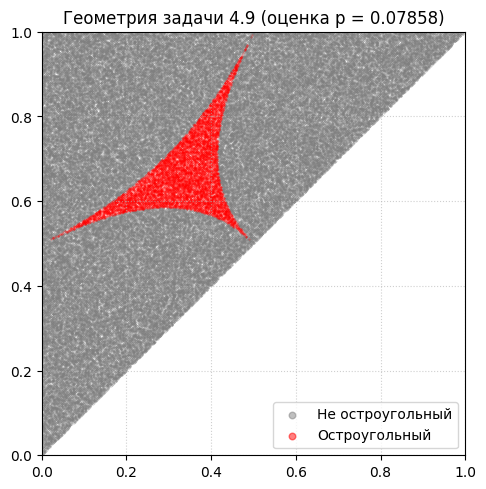

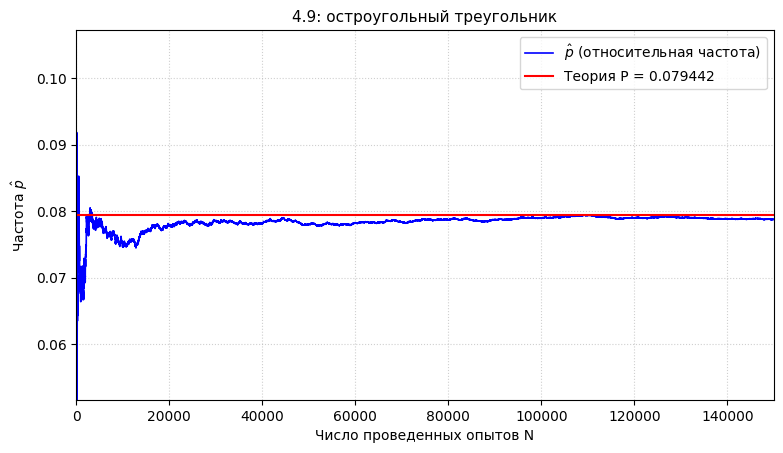

Оценка вероятности: p_hat = 0.078773 (теория = 0.079442)


In [105]:
P_4_9 = 3 * np.log(2) - 2

N_sim = 150_000
u = np.random.uniform(0, 1, (N_sim, 2))
u.sort(axis=1)
x_9 = u[:, 0]
y_9 = u[:, 1]

s1 = x_9
s2 = y_9 - x_9
s3 = 1.0 - y_9
acute = (s1**2 + s2**2 > s3**2) & (s1**2 + s3**2 > s2**2) & (s2**2 + s3**2 > s1**2)

plt.figure(figsize=(5.5, 5.5))
plt.scatter(x_9[~acute], y_9[~acute], s=0.1, c='gray', alpha=0.5, label='Не остроугольный')
plt.scatter(x_9[acute], y_9[acute], s=0.1, c='red', alpha=0.5, label='Остроугольный')
plt.gca().set_aspect('equal')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.title(f'Геометрия задачи 4.9 (оценка p = {np.mean(acute):.5f})')
plt.legend(markerscale=15)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

def sim_4_9():
    u1, u2 = random.random(), random.random()
    x_i, y_i = (u1, u2) if u1 <= u2 else (u2, u1)
    a1, a2, a3 = x_i, y_i - x_i, 1.0 - y_i
    return (a1*a1 + a2*a2 > a3*a3) and (a1*a1 + a3*a3 > a2*a2) and (a2*a2 + a3*a3 > a1*a1)

plot_stability(sim_4_9, P_4_9, N=150_000, title='4.9: остроугольный треугольник')


**4.10.** В круге радиуса 1 наудачу выбирается отрезок. Найти вероятность того, что длина этого отрезка будет меньше радиуса круга.

*Ответ из методички:* $1 - \frac{3\sqrt{3}}{4\pi} \approx 0{,}5865033284336559$.


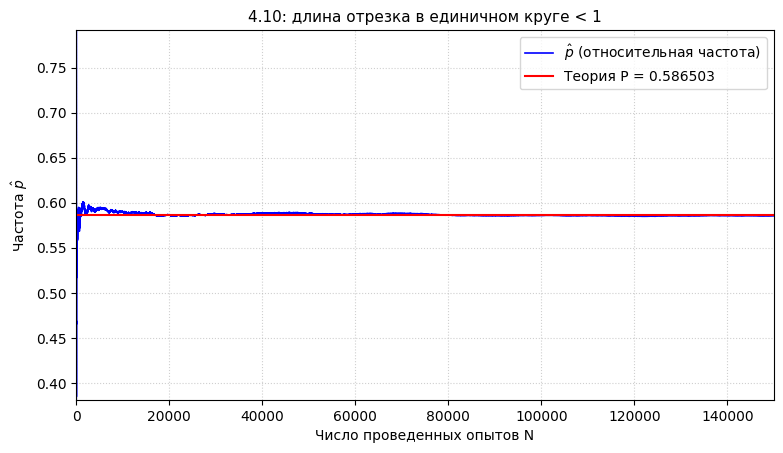

Оценка вероятности: p_hat = 0.585433 (теория = 0.586503)


In [106]:
import math

P_4_10 = 1 - (3 * np.sqrt(3)) / (4 * np.pi)

def sim_4_10():
    r1 = math.sqrt(random.random())
    a1 = random.uniform(0, 2 * math.pi)
    r2 = math.sqrt(random.random())
    a2 = random.uniform(0, 2 * math.pi)
    dx = r1 * math.cos(a1) - r2 * math.cos(a2)
    dy = r1 * math.sin(a1) - r2 * math.sin(a2)
    return math.hypot(dx, dy) < 1.0

plot_stability(sim_4_10, P_4_10, N=150_000, title='4.10: длина отрезка в единичном круге < 1')


**4.11.** $n$ лиц условились о встрече между 10 и 11 часами утра, причем договорились ждать друг друга не более $60 \cdot q$ минут ($q < 1$). Считая, что момент прихода на встречу выбирается каждым «наудачу» в пределах указанного часа, докажите, что вероятность того, что встреча состоится, определяется равенством $P_n = n q^{n-1} - (n - 1) q^n$. Проверить формулу для $n = 2$ и $n = 3$. Для $n = 3$ найти также вероятность того, что встреча по крайней мере двух лиц состоится.


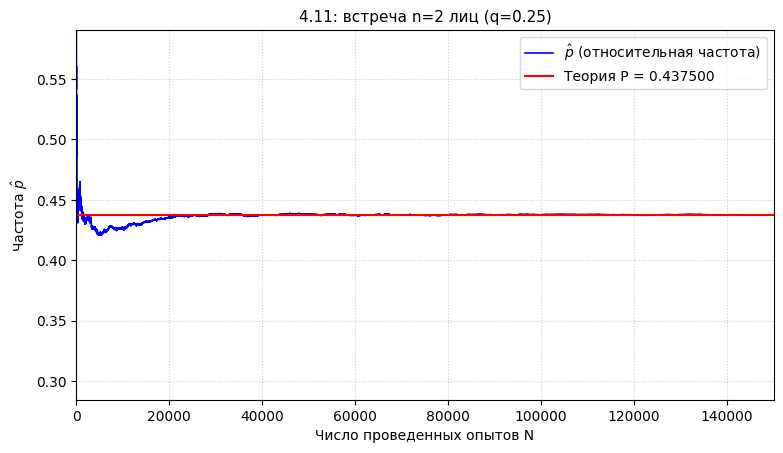

Оценка вероятности: p_hat = 0.437280 (теория = 0.437500)


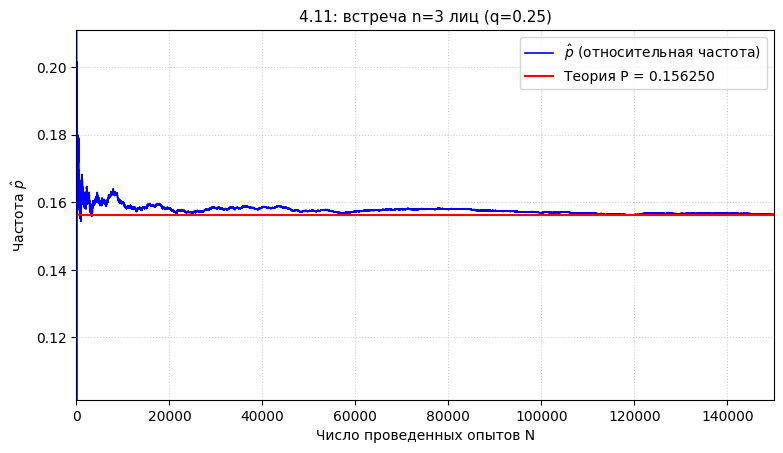

Оценка вероятности: p_hat = 0.156400 (теория = 0.156250)


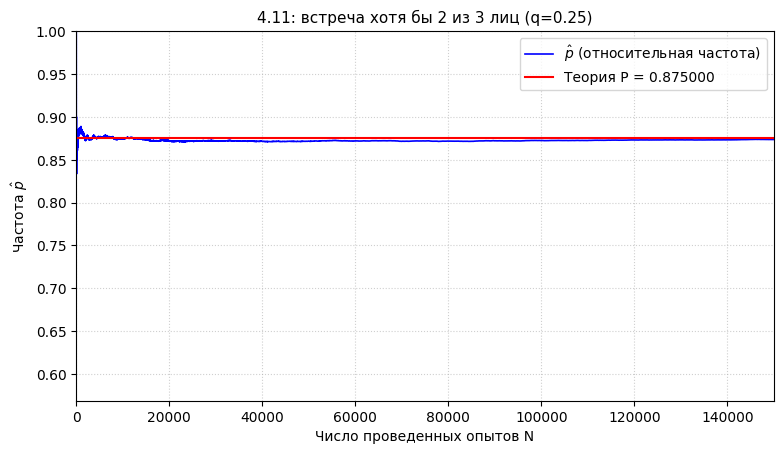

Оценка вероятности: p_hat = 0.873560 (теория = 0.875000)


In [107]:
q = 0.25
P2_theor = 2 * q - q**2
P3_theor = 3 * q**2 - 2 * q**3
P3_at_least_2_theor = 1 - max(0.0, 1 - 2 * q)**3

def sim_4_11_n(n_people):
    arr = [random.random() for _ in range(n_people)]
    return (max(arr) - min(arr)) <= q

def sim_4_11_at_least_2():
    arr = sorted([random.random() for _ in range(3)])
    return (arr[1] - arr[0] <= q) or (arr[2] - arr[1] <= q)

plot_stability(lambda: sim_4_11_n(2), P2_theor, N=150_000, title='4.11: встреча n=2 лиц (q=0.25)')
plot_stability(lambda: sim_4_11_n(3), P3_theor, N=150_000, title='4.11: встреча n=3 лиц (q=0.25)')
plot_stability(sim_4_11_at_least_2, P3_at_least_2_theor, N=150_000, title='4.11: встреча хотя бы 2 из 3 лиц (q=0.25)')


**4.12.*** *(Продолжение)* Пусть $n$ лиц имеют время ожидания $w_1, w_2, \dots, w_n$, выраженные в долях от общего интервала времени. Считая, что момент прихода на встречу выбирается каждым «наудачу» в пределах указанного часа, докажите, что вероятность того, что встреча состоится, определяется следующими равенствами для:

**а)** $n = 2$;

**б)** $n = 3$;

**в)** $n = 3, \; w_1 = \frac{1}{4}, \; w_2 = \frac{1}{3}, \; w_3 = \frac{1}{2}$ (15 минут, 20 минут, 30 минут);

**г)** $n = 4$:

$$a) \; P_2 = 1 - \frac{(1-w_1)^2}{2} - \frac{(1-w_2)^2}{2};$$

$$b) \; P_3 = w_1 w_2 + w_1 w_3 + w_2 w_3 - \frac{1}{2}(w_1 w_2^2 + w_1 w_3^2 + w_2 w_3^2) - \frac{1}{3}w_1^3 - \frac{1}{6}w_2^3;$$

$$c) \; P_3 = \frac{1435}{5184} \approx 0{,}27681;$$

$$d) \; P_4 = w_1 w_2 w_3 + w_1 w_2 w_4 + w_1 w_3 w_4 + w_2 w_3 w_4 - \frac{w_4^2}{2}(w_1 w_2 + w_1 w_3 + w_2 w_3) - \frac{w_3^3}{6}(w_1 + w_2) - \frac{w_1 w_2 w_3^2}{2} - \frac{w_1 w_2^3}{3} - \frac{w_1^4}{4} - \frac{w_2^4}{12}.$$


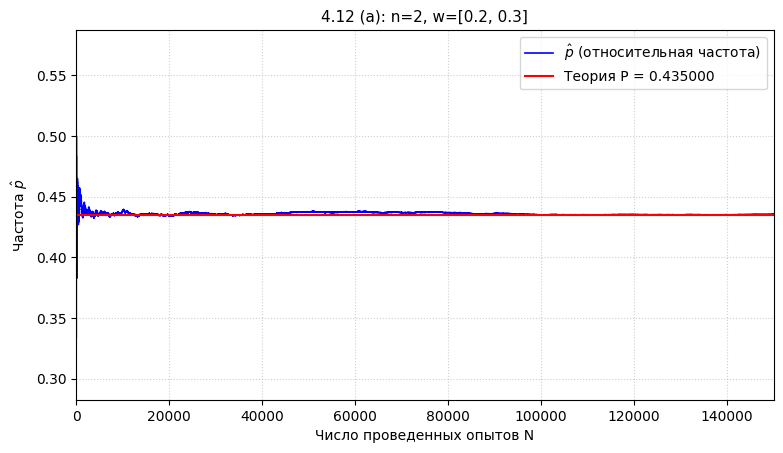

Оценка вероятности: p_hat = 0.435873 (теория = 0.435000)


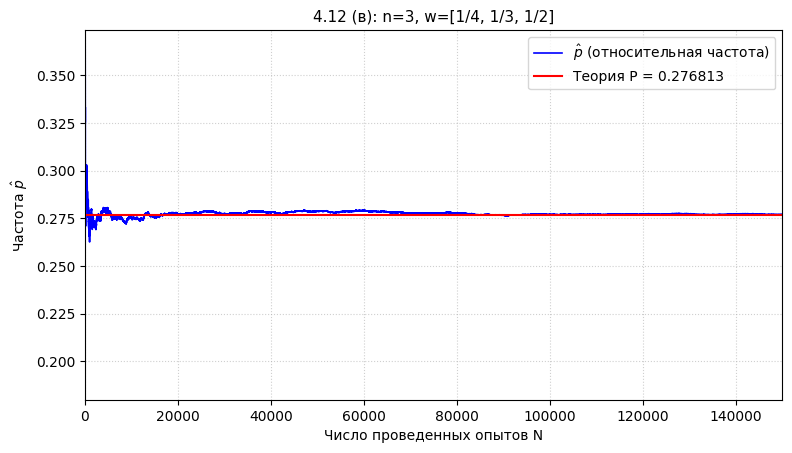

Оценка вероятности: p_hat = 0.277147 (теория = 0.276813)


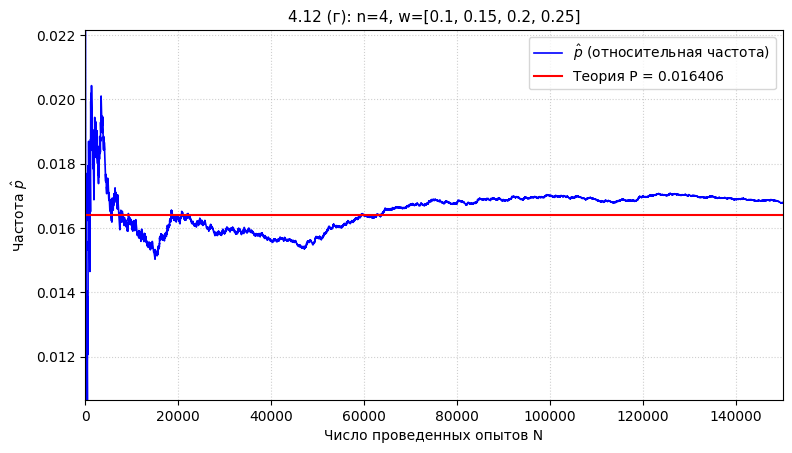

Оценка вероятности: p_hat = 0.016793 (теория = 0.016406)


In [108]:
def sim_4_12(w_list):
    t = [random.random() for _ in w_list]
    t_max = max(t)
    return all(ti + wi >= t_max for ti, wi in zip(t, w_list))

w_a = [0.2, 0.3]
P2_12 = 1 - ((1 - w_a[0])**2) / 2 - ((1 - w_a[1])**2) / 2

w_c = [1/4, 1/3, 1/2]
w1, w2, w3 = w_c
P3_12_c = (w1*w2 + w1*w3 + w2*w3
           - 0.5*(w1*w2**2 + w1*w3**2 + w2*w3**2)
           - (w1**3)/3 - (w2**3)/6)

w_d = [0.1, 0.15, 0.2, 0.25]
w1, w2, w3, w4 = w_d
P4_12 = (w1*w2*w3 + w1*w2*w4 + w1*w3*w4 + w2*w3*w4
         - (w4**2 / 2)*(w1*w2 + w1*w3 + w2*w3)
         - (w3**3 / 6)*(w1 + w2)
         - (w1*w2*w3**2)/2 - (w1*w2**3)/3 - (w1**4)/4 - (w2**4)/12)

plot_stability(lambda: sim_4_12(w_a), P2_12, N=150_000, title='4.12 (a): n=2, w=[0.2, 0.3]')
plot_stability(lambda: sim_4_12(w_c), 1435/5184, N=150_000, title='4.12 (в): n=3, w=[1/4, 1/3, 1/2]')
plot_stability(lambda: sim_4_12(w_d), P4_12, N=150_000, title='4.12 (г): n=4, w=[0.1, 0.15, 0.2, 0.25]')


**4.13.** В корзину с $n$ шарами опускают белый шар. Найдите вероятность того, что извлеченный шар окажется белым, если первоначальное распределение белых шаров в корзине имеет биномиальное распределение с параметром $p$. Решите задачу для общего случая и для конкретных $n = 10, \; p = \frac{1}{3}$.

*Ответ из методички:* $0{,}15625$.


Общая формула: P = (n*p + 1) / (n + 1) = 0.393939


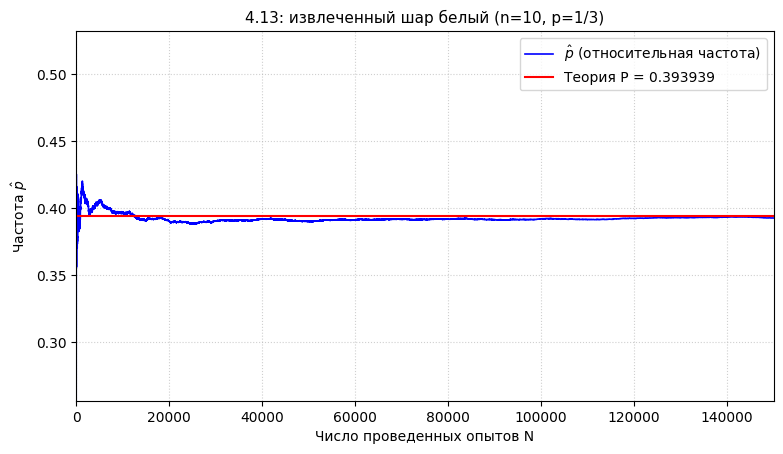

Оценка вероятности: p_hat = 0.392393 (теория = 0.393939)


In [109]:
n_balls = 10
p_bin = 1 / 3
P_4_13 = (n_balls * p_bin + 1) / (n_balls + 1)
print(f'Общая формула: P = (n*p + 1) / (n + 1) = {P_4_13:.6f}')

def sim_4_13():
    white_init = np.random.binomial(n_balls, p_bin)
    return random.random() < (white_init + 1) / (n_balls + 1)

plot_stability(sim_4_13, P_4_13, N=150_000, title='4.13: извлеченный шар белый (n=10, p=1/3)')


**4.14.** Имеется две корзины с белыми и черными шарами. В первой корзине всего 6 шаров, при этом количество белых шаров распределено по биномиальному закону с параметрами $n = 3$ и $p = 0{,}8$. Во второй корзине имеется всего 11 шаров, при этом количество белых шаров распределено по биномиальному закону с параметрами $n = 4$ и $p = 0{,}7$. Из обеих корзин все шары перекладываются в третью корзину.

**1)** Какова вероятность $\mathbb{P}(A)$, что случайно вынутый из третьей корзины шар окажется белым (событие $A$)?

**2)** Найдите условную вероятность $\mathbb{P}(H|A)$ того, что случайно вынутый из третьей корзины шар первоначально находился в первой корзине (событие $H$), при условии, что он белый (событие $A$)?

*Ответ из методички:* 1) $\mathbb{P}(A) = 0{,}3059$; 2) $\mathbb{P}(H|A) = 0{,}4615$.


Теор P(A) = 0.3059
Теор P(H|A) = 0.4615
Оценка P(A) = 0.3069
Оценка P(H|A) = 0.4636


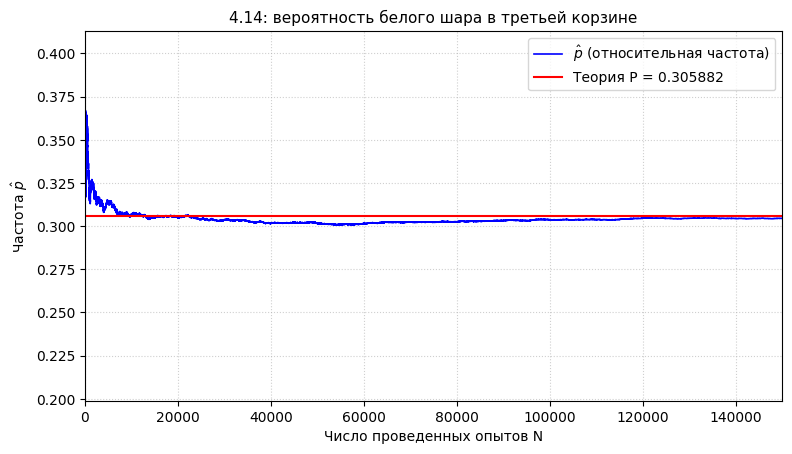

Оценка вероятности: p_hat = 0.304460 (теория = 0.305882)


In [110]:
E_X1 = 3 * 0.8
E_X2 = 4 * 0.7
P_A_14 = (E_X1 + E_X2) / 17
P_H_given_A_14 = E_X1 / (E_X1 + E_X2)

print(f'Теор P(A) = {P_A_14:.4f}')
print(f'Теор P(H|A) = {P_H_given_A_14:.4f}')

def sim_4_14_a():
    w1 = np.random.binomial(3, 0.8)
    w2 = np.random.binomial(4, 0.7)
    return random.random() < (w1 + w2) / 17

N_14 = 150_000
w1_arr = np.random.binomial(3, 0.8, N_14)
w2_arr = np.random.binomial(4, 0.7, N_14)
idx = np.random.randint(0, 17, N_14)
is_from_b1 = idx < 6
is_white = np.where(is_from_b1, idx < w1_arr, (idx - 6) < w2_arr)
print(f'Оценка P(A) = {np.mean(is_white):.4f}')
print(f'Оценка P(H|A) = {np.mean(is_from_b1[is_white]):.4f}')

plot_stability(sim_4_14_a, P_A_14, N=150_000, title='4.14: вероятность белого шара в третьей корзине')


**4.15.** В прямоугольной области, заданной ограничениями $|x| \le 20$ и $|y| \le 8$, случайным образом выбираются две точки: $(x_1, y_1)$ и $(x_2, y_2)$. Пусть $A$ и $B$ – события, состоящие в том, что:

* $A$ — расстояние между выбранными точками меньше 11;
* $B$ — модуль разности $|x_1 - x_2|$ меньше 14.

Найдите приближенно, методом Монте-Карло:
1) вероятность $\mathbb{P}(A)$;
2) условную вероятность $\mathbb{P}(A|B)$.

*Указание:* получите в заданной прямоугольной области 100 000 пар точек и, используя все эти точки, найдите ответы, округляя их до одного знака после запятой.

*Ответ из методички:* 1) $\mathbb{P}(A) = 0{,}37$; 2) $\mathbb{P}(A|B) = 0{,}64$.


P(A) = 0.37 (округл: 0.4)
P(A|B) = 0.64 (округл: 0.6)


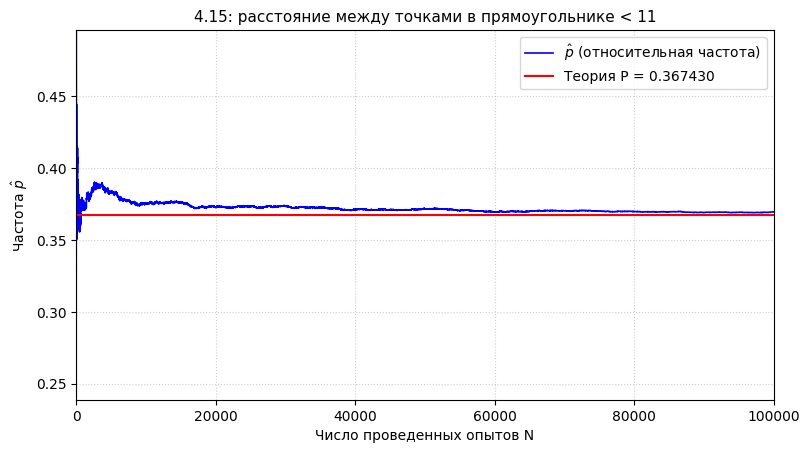

Оценка вероятности: p_hat = 0.369560 (теория = 0.367430)


In [111]:
N_15 = 100_000
x1 = np.random.uniform(-20, 20, N_15)
y1 = np.random.uniform(-8, 8, N_15)
x2 = np.random.uniform(-20, 20, N_15)
y2 = np.random.uniform(-8, 8, N_15)

ev_A_15 = np.hypot(x1 - x2, y1 - y2) < 11
ev_B_15 = np.abs(x1 - x2) < 14
p_a_est_15 = np.mean(ev_A_15)
p_ab_est_15 = np.mean(ev_A_15[ev_B_15])

print(f'P(A) = {p_a_est_15:.2f} (округл: {p_a_est_15:.1f})')
print(f'P(A|B) = {p_ab_est_15:.2f} (округл: {p_ab_est_15:.1f})')

def sim_4_15_a():
    return math.hypot(random.uniform(-20, 20) - random.uniform(-20, 20), random.uniform(-8, 8) - random.uniform(-8, 8)) < 11

plot_stability(sim_4_15_a, p_a_est_15, N=100_000, title='4.15: расстояние между точками в прямоугольнике < 11')


**4.16.** В области, ограниченной эллипсом $\left(\frac{u}{23}\right)^2 + \left(\frac{v}{6}\right)^2 = 1$, случайным образом выбираются две точки. Пусть $A$ и $B$ – события, состоящие в том, что:

* $A$ — расстояние между выбранными точками меньше 9,2;
* $B$ — координаты первой точки больше 0, а координаты второй точки меньше 0.

Найдите приближенно, методом Монте-Карло:
1) вероятность $\mathbb{P}(A)$;
2) условную вероятность $\mathbb{P}(A|B)$.

*Указание:* получите внутри заданного эллипса 100 000 пар точек и, используя все эти пары точек, найдите ответы, округляя их до одного знака после запятой.

*Ответ из методички:* 1) $\mathbb{P}(A) = 0{,}35$; 2) $\mathbb{P}(A|B) = 0{,}07$.


P(A) = 0.35 (округл: 0.4)
P(A|B) = 0.07 (округл: 0.1)


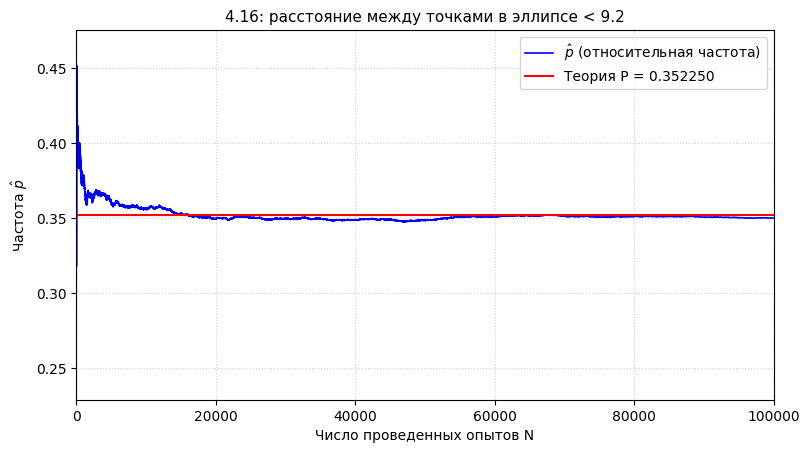

Оценка вероятности: p_hat = 0.350100 (теория = 0.352250)


In [112]:
N_16 = 100_000
r1 = np.sqrt(np.random.uniform(0, 1, N_16))
phi1 = np.random.uniform(0, 2 * np.pi, N_16)
u1, v1 = 23 * r1 * np.cos(phi1), 6 * r1 * np.sin(phi1)

r2 = np.sqrt(np.random.uniform(0, 1, N_16))
phi2 = np.random.uniform(0, 2 * np.pi, N_16)
u2, v2 = 23 * r2 * np.cos(phi2), 6 * r2 * np.sin(phi2)

ev_A_16 = np.hypot(u1 - u2, v1 - v2) < 9.2
ev_B_16 = (u1 > 0) & (v1 > 0) & (u2 < 0) & (v2 < 0)
p_a_est_16 = np.mean(ev_A_16)
p_ab_est_16 = np.mean(ev_A_16[ev_B_16])

print(f'P(A) = {p_a_est_16:.2f} (округл: {p_a_est_16:.1f})')
print(f'P(A|B) = {p_ab_est_16:.2f} (округл: {p_ab_est_16:.1f})')

def sim_4_16_a():
    ra = math.sqrt(random.random())
    pa = random.uniform(0, 2 * math.pi)
    rb = math.sqrt(random.random())
    pb = random.uniform(0, 2 * math.pi)
    return math.hypot(23 * ra * math.cos(pa) - 23 * rb * math.cos(pb), 6 * ra * math.sin(pa) - 6 * rb * math.sin(pb)) < 9.2

plot_stability(sim_4_16_a, p_a_est_16, N=100_000, title='4.16: расстояние между точками в эллипсе < 9.2')


**4.17.** В кубе объема 1 случайным образом выбираются точки $A, B$ и $C$. Пусть $R, S$ и $T$ – события, состоящие в том, что:

* $R$ — наименьший угол в треугольнике $ABC$ меньше $26{,}7^\circ$;
* $S$ — наибольший угол в треугольнике $ABC$ меньше $81{,}9^\circ$;
* $T$ — треугольник $ABC$ остроугольный.

Найдите приближенно, методом Монте-Карло:
1) условную вероятность $\mathbb{P}(R|T)$;
2) условную вероятность $\mathbb{P}(S|T)$.

*Указание:* получите 100 000 остроугольных треугольников $ABC$ и, используя все эти треугольники, найдите ответы, округляя их до одного знака после запятой.

*Ответ из методички:* 1) $\mathbb{P}(R|T) = 0{,}11$; 2) $\mathbb{P}(S|T) = 0{,}65$.


P(R|T) = 0.11 (округл: 0.1)
P(S|T) = 0.66 (округл: 0.7)


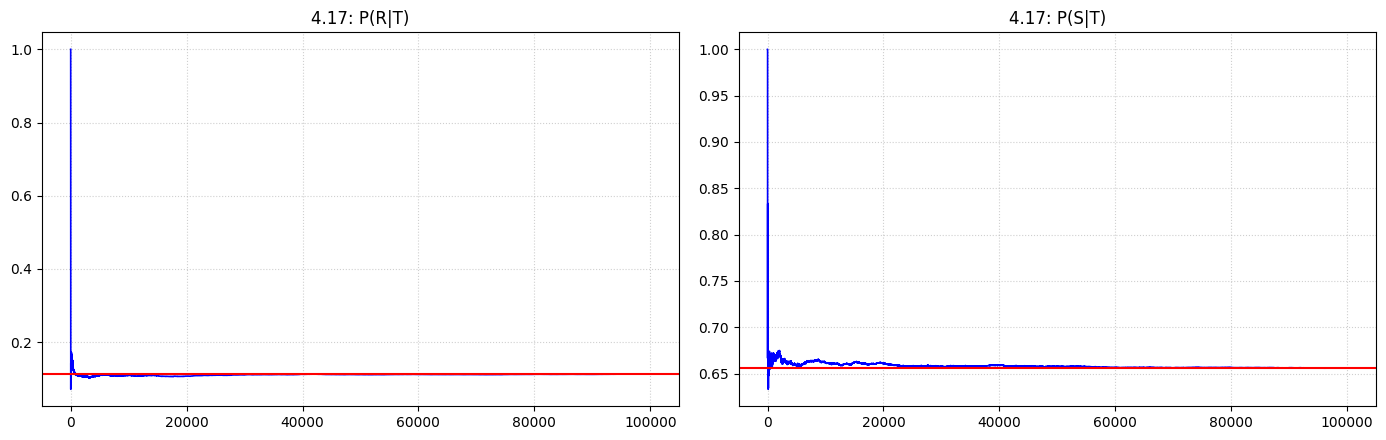

In [113]:
cos_min_thresh = np.cos(np.radians(26.7))
cos_max_thresh = np.cos(np.radians(81.9))

acute_cos_min = []
acute_cos_max = []

while sum(len(arr) for arr in acute_cos_min) < 100_000:
    pts = np.random.uniform(0, 1, (300_000, 3, 3))
    d2_ab = np.sum((pts[:, 0] - pts[:, 1])**2, axis=1)
    d2_bc = np.sum((pts[:, 1] - pts[:, 2])**2, axis=1)
    d2_ca = np.sum((pts[:, 2] - pts[:, 0])**2, axis=1)
    d2 = np.sort(np.stack([d2_ab, d2_bc, d2_ca], axis=1), axis=1)
    s1, s2, s3 = d2[:, 0], d2[:, 1], d2[:, 2]
    is_acute = (s1 + s2) > s3
    s1, s2, s3 = s1[is_acute], s2[is_acute], s3[is_acute]
    acute_cos_min.append((s2 + s3 - s1) / (2 * np.sqrt(s2 * s3)))
    acute_cos_max.append((s1 + s2 - s3) / (2 * np.sqrt(s1 * s2)))

c_min_all = np.concatenate(acute_cos_min)[:100_000]
c_max_all = np.concatenate(acute_cos_max)[:100_000]

ev_R_17 = c_min_all > cos_min_thresh
ev_S_17 = c_max_all > cos_max_thresh
p_rt_17 = np.mean(ev_R_17)
p_st_17 = np.mean(ev_S_17)

print(f'P(R|T) = {p_rt_17:.2f} (округл: {p_rt_17:.1f})')
print(f'P(S|T) = {p_st_17:.2f} (округл: {p_st_17:.1f})')

trials_17 = np.arange(1, 100_001)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.plot(trials_17, np.cumsum(ev_R_17) / trials_17, 'b-', lw=1.2)
ax1.axhline(y=p_rt_17, color='red', lw=1.5)
ax1.set_title('4.17: P(R|T)')
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.plot(trials_17, np.cumsum(ev_S_17) / trials_17, 'b-', lw=1.2)
ax2.axhline(y=p_st_17, color='red', lw=1.5)
ax2.set_title('4.17: P(S|T)')
ax2.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


In [4]:
from collections import deque
import itertools

In [ ]:
def set_direction(direction) -> int:
    if direction != 0:
        if direction < 0:
            return -1
        else:
            return 1

    return 0

def have_value_moves(A, B, C) -> bool:
    direction_x = B[0] - A[0]
    direction_y = B[1] - A[1]

    direction_x = set_direction(direction_x)
    direction_y = set_direction(direction_y)

    A_x = (A[0] + direction_x, A[1])
    A_y = (A[0], A[1] + direction_y)

    x_is_value, y_is_value = False, False

    if A_x != C and direction_x != 0:
        x_is_value = True

    if A_y != C and direction_y != 0:
        y_is_value = True

    return x_is_value or y_is_value


def move(A, B, C, v) -> int:
    direction_x = set_direction(B[0] - A[0])
    direction_y = set_direction(B[1] - A[1])

    if direction_x == 0 and direction_y == 0:
        return 1

    s = 0
    A_x = (A[0] + direction_x, A[1])
    A_y = (A[0], A[1] + direction_y)

    if have_value_moves(A, B, C):
        if direction_x != 0:
            if A_x == C:
                pass

            if A_x != C and A_x not in v:
                v.add(A_x)
                s += move(A_x, B, C, v.copy())
            else:
                pass
        
        if direction_y != 0:
            if A_y == C:
                pass

            if A_y != C and A_y not in v:
                v.add(A_y)
                s += move(A_y, B, C, v.copy())
            else:
                pass

    else:
        if A_x == C:
            A_c1 = (A[0], A[1] + 1)
            A_c2 = (A[0], A[1] - 1)
        else:
            A_c1 = (A[0] + 1, A[1])
            A_c2 = (A[0] - 1, A[1])


        v.add(A_c1)
        v.add(A_c2)
        s += move(A_c1, B, C, v.copy())
        s += move(A_c2, B, C, v.copy())

    return s

def calculate_count_min_paths(dots):
    A, B, C = map(tuple, dots)

    v = set()
    v.add(A)

    return move(A, B, C, v)

dots = [[0, 0], [5, 5], [3, 3]]

print(calculate_count_min_paths(dots))

TypeError: unhashable type: 'list'

In [ ]:
from collections import deque

def bfs_min_dist(A, B, C, w, h):
    if A == B:
        return 0

    visited = {A}
    queue = deque([(A, 0)])

    while queue:
        pos, dist = queue.popleft()

        for dx, dy in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
            nxt = (pos[0] + dx, pos[1] + dy)

            if nxt[0] < 0 or nxt[0] >= w or nxt[1] < 0 or nxt[1] >= h:
                continue

            if nxt == C or nxt in visited:
                continue

            if nxt == B:
                return dist + 1

            visited.add(nxt)
            queue.append((nxt, dist + 1))

    return -1


def find_all_min_paths(A, B, C, w, h):
    min_dist = bfs_min_dist(A, B, C, w, h)

    if min_dist == -1:
        return []

    all_paths = []
    stack = [(A, [A])]

    while stack:
        pos, path = stack.pop()

        if len(path) - 1 > min_dist:
            continue

        if pos == B:
            if len(path) - 1 == min_dist:
                all_paths.append(path)
            continue

        for dx, dy in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
            nxt = (pos[0] + dx, pos[1] + dy)

            if nxt[0] < 0 or nxt[0] >= w or nxt[1] < 0 or nxt[1] >= h:
                continue

            if nxt == C or nxt in path:
                continue

            stack.append((nxt, path + [nxt]))

    return all_paths


w, h = 6, 6
A = (0, 0)
B = (5, 5)
C = (3, 3)

paths = find_all_min_paths(A, B, C, w, h)

print(f'min distance: {bfs_min_dist(A, B, C, w, h)}')
print(f'paths count: {len(paths)}')

for i, p in enumerate(paths):
    print(f'path {i + 1}: {p}')


In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(8, 8))

colors = plt.cm.tab20(np.linspace(0, 1, max(len(paths), 1)))

def draw_grid():
    ax.clear()
    ax.set_xlim(-0.5, w - 0.5)
    ax.set_ylim(-0.5, h - 0.5)
    ax.set_aspect('equal')
    ax.set_xticks(range(w))
    ax.set_yticks(range(h))
    ax.grid(True, linewidth=0.5, alpha=0.3)

    ax.plot(*A, 'gs', markersize=18, zorder=5)
    ax.text(A[0], A[1] + 0.3, 'A', ha='center', fontsize=12, fontweight='bold', color='green')

    ax.plot(*B, 'bs', markersize=18, zorder=5)
    ax.text(B[0], B[1] + 0.3, 'B', ha='center', fontsize=12, fontweight='bold', color='blue')

    ax.plot(*C, 'rx', markersize=20, markeredgewidth=3, zorder=5)
    ax.text(C[0], C[1] + 0.3, 'C', ha='center', fontsize=12, fontweight='bold', color='red')

lines = []

def animate(frame):
    draw_grid()
    for i in range(frame + 1):
        path = paths[i]
        xs = [p[0] for p in path]
        ys = [p[1] for p in path]
        alpha = 0.15 if i < frame else 0.9
        lw = 1.5 if i < frame else 3
        ax.plot(xs, ys, '-o', color=colors[i % len(colors)], alpha=alpha,
                linewidth=lw, markersize=3, zorder=3)
    ax.set_title(f'path {frame + 1} / {len(paths)}', fontsize=14)

anim = FuncAnimation(fig, animate, frames=len(paths), interval=300, repeat=False)
plt.close(fig)
HTML(anim.to_jshtml())
